# Fixed-t1 five-method noise benchmark

This notebook reads only the strict 100-repeat aggregate produced after all
600 current-hash shards pass validation. Accuracy summaries exclude native
method failures rather than treating failure as accuracy zero. Ribbons are
empirical 2.5th--97.5th percentiles across repeat indices, not confidence
intervals for biological generalization.

The corrected estimand holds t1 fixed, reapplies realized-tensor lineage
eligibility before every fit, passes the same ordered clone IDs to all methods,
and uses the sole inclusive ChronoClone post-fit cutoff `silhouette >= -0.1`.


Publication path labels were normalized after the recorded execution. Scientific code cells and displayed numerical and figure results were preserved; the current kernel entry uses the neutral runtime alias.

In [1]:
from pathlib import Path
import hashlib
import importlib.metadata
import json
import platform
import xml.etree.ElementTree as ET
import warnings
import matplotlib as mpl
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore", message="FigureCanvasAgg is non-interactive.*")
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
NOTEBOOK_NAME = "0003_t1_locked_method_noise_results.ipynb"
AGGREGATE = ROOT / "results" / "aggregate"
FIGURES = ROOT / "figures" / "validation_five_method"
FIGURES.mkdir(parents=True, exist_ok=True)
ENVIRONMENT = {
    "manager": "micromamba",
    "name": "chronoclone",
    "historical_macbook_path": "/path/to/ChronoClone/.runtime/chronoclone",
    "current_prefix": __import__("sys").prefix,
    "kernel": "chronoclone",
    "python": platform.python_version(),
    "versions": {name: importlib.metadata.version(name) for name in ["numpy", "pandas", "scipy", "scikit-learn", "scanpy", "matplotlib", "nbformat", "nbclient"]},
    "execution_command": f"python ../run_notebook.py {Path('notebooks') / NOTEBOOK_NAME}",
}
mpl.rcParams["svg.fonttype"] = "none"
mpl.rcParams["svg.hashsalt"] = "chronoclone-paper"
METHODS = ["ChronoClone", "CLADES preprocessing", "Cyclone abundance-only", "K-means", "Ward"]
COLORS = dict(zip(METHODS, ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00"]))
ENVIRONMENT


{'manager': 'micromamba',
 'name': 'chronoclone',
 'historical_macbook_path': '/path/to/ChronoClone/.runtime/chronoclone',
 'current_prefix': '/path/to/ChronoClone/.runtime/chronoclone',
 'kernel': 'chronoclone',
 'python': '3.11.15',
 'versions': {'numpy': '2.4.6',
  'pandas': '2.3.3',
  'scipy': '1.17.1',
  'scikit-learn': '1.9.0',
  'scanpy': '1.11.5',
  'matplotlib': '3.11.0',
  'nbformat': '5.10.4',
  'nbclient': '0.11.0'},
 'execution_command': 'python ../run_notebook.py notebooks/0003_t1_locked_method_noise_results.ipynb'}

In [2]:
def sha256(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

metadata = json.loads((AGGREGATE / "aggregation_metadata.json").read_text())
assert metadata["status"] == "pass"
for artifact_name, expected in metadata["artifact_sha256"].items():
    assert sha256(AGGREGATE / artifact_name) == expected
for artifact_name, record in metadata.get("omitted_large_artifacts", {}).items():
    assert len(record["sha256"]) == 64 and record["bytes"] > 100_000_000
summary = pd.read_csv(AGGREGATE / "native_method_noise_summary.csv")
completeness = pd.read_csv(AGGREGATE / "result_completeness.csv")
eligibility = pd.read_csv(AGGREGATE / "eligibility_summary.csv")
selective = pd.read_csv(AGGREGATE / "chronoclone_selective_summary.csv")
same_retained = pd.read_csv(AGGREGATE / "same_retained_subset_summary.csv")
failures = pd.read_csv(AGGREGATE / "method_failure_counts.csv")
assert len(summary) == len(completeness) == len(same_retained) == 5 * 51 * 51
assert len(eligibility) == len(selective) == 51 * 51
assert not summary.duplicated(["method", "gaussian_pct", "uniform_pct"]).any()
assert not eligibility.duplicated(["gaussian_pct", "uniform_pct"]).any()
assert (completeness["n_expected"] == 100).all()
assert (completeness["n_success"] + completeness["n_method_failure"] == 100).all()
metadata_display = dict(metadata)
metadata_display["t1_lock_validated"] = metadata_display.get("t1_lock_validated", metadata_display.get("day0_lock_validated"))
metadata_display.pop("day0_lock_validated", None)
metadata_display.pop("schema", None)
display(pd.DataFrame([metadata_display]).T.rename(columns={0: "value"}))
display(completeness.groupby("method", sort=False)[["n_expected", "n_success", "n_method_failure"]].sum())


,value
aggregation_completed_at_utc,2026-08-13T20:48:04.342186+00:00
artifact_sha256,{'chronoclone_selective_summary.csv': '612d549...
chronoclone_selective_summary_rows,2601
cyclone_uniform_invariance_validated,True
deterministic_clean_baseline_validated,True
eligibility_summary_rows,2601
expected_chunks,600
expected_rows,1300500
five_method_common_cohort_validated,True
hash_contract,{'chronoclone_package_tree_sha256': '3a5bbeb6a...


,n_expected,n_success,n_method_failure
method,,,
ChronoClone,260100,260100,0
CLADES preprocessing,260100,260100,0
Cyclone abundance-only,260100,11934,248166
K-means,260100,260100,0
Ward,260100,260100,0


## Full-cohort accuracy

The two axis plots isolate one noise mechanism. Each method heatmap then shows
the complete Gaussian-then-uniform grid on a common 0--1 ARI scale. Gray cells
have no successful native fit and therefore no accuracy estimate.


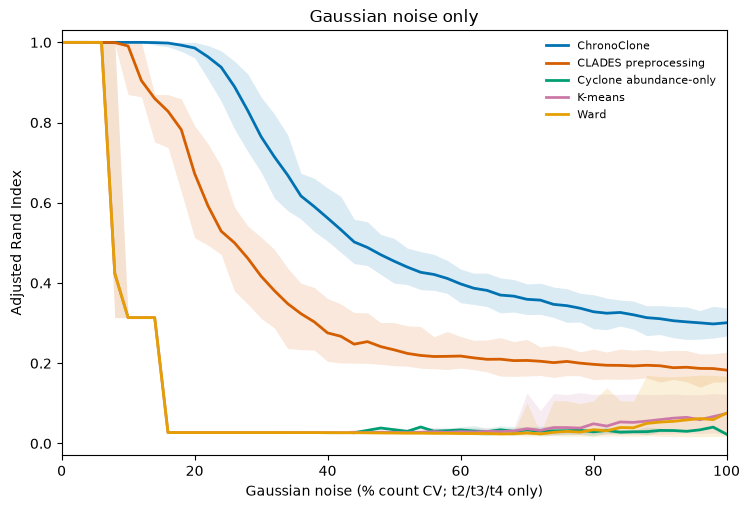

/path/to/ChronoClone/ChronoClone_paper/benchmarks/ode_noise/figures/validation_five_method/gaussian_only_mean_ari_by_method.svg


In [3]:
# Plot-specific shaping and full construction: Gaussian noise only mean ARI
axis_data = summary.loc[summary["uniform_pct"].eq(0)].copy()
fig, ax = plt.subplots(figsize=(7.6, 5.2))
for method in METHODS:
    data = axis_data.loc[axis_data["method"].eq(method)].sort_values('gaussian_pct')
    x = data['gaussian_pct'].to_numpy(float)
    mean = data["ari_mean"].to_numpy(float)
    lower = data["ari_q025"].to_numpy(float)
    upper = data["ari_q975"].to_numpy(float)
    finite = np.isfinite(mean)
    if finite.any():
        ax.plot(x[finite], mean[finite], color=COLORS[method], linewidth=2.0, label=method)
        band = finite & np.isfinite(lower) & np.isfinite(upper)
        if band.any():
            ax.fill_between(x[band], lower[band], upper[band], color=COLORS[method], alpha=0.14, linewidth=0)
ax.set_xlim(0, 100)
ax.set_ylim(-0.03, 1.03)
ax.set_xlabel('Gaussian noise (% count CV; t2/t3/t4 only)')
ax.set_ylabel("Adjusted Rand Index")
ax.set_title('Gaussian noise only')
handles, labels = ax.get_legend_handles_labels()
if handles:
    ax.legend(handles, labels, frameon=False, fontsize=8)
fig.tight_layout()
output_path = FIGURES / 'gaussian_only_mean_ari_by_method.svg'
fig.savefig(output_path, format="svg", bbox_inches="tight")
plt.show()
print(output_path)


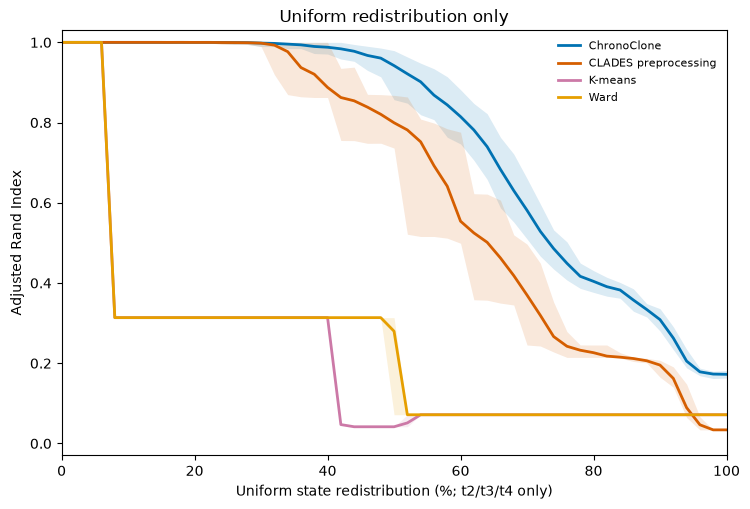

/path/to/ChronoClone/ChronoClone_paper/benchmarks/ode_noise/figures/validation_five_method/uniform_only_mean_ari_by_method.svg


In [4]:
# Plot-specific shaping and full construction: Uniform redistribution only mean ARI
axis_data = summary.loc[summary["gaussian_pct"].eq(0)].copy()
fig, ax = plt.subplots(figsize=(7.6, 5.2))
for method in METHODS:
    data = axis_data.loc[axis_data["method"].eq(method)].sort_values('uniform_pct')
    x = data['uniform_pct'].to_numpy(float)
    mean = data["ari_mean"].to_numpy(float)
    lower = data["ari_q025"].to_numpy(float)
    upper = data["ari_q975"].to_numpy(float)
    finite = np.isfinite(mean)
    if finite.any():
        ax.plot(x[finite], mean[finite], color=COLORS[method], linewidth=2.0, label=method)
        band = finite & np.isfinite(lower) & np.isfinite(upper)
        if band.any():
            ax.fill_between(x[band], lower[band], upper[band], color=COLORS[method], alpha=0.14, linewidth=0)
ax.set_xlim(0, 100)
ax.set_ylim(-0.03, 1.03)
ax.set_xlabel('Uniform state redistribution (%; t2/t3/t4 only)')
ax.set_ylabel("Adjusted Rand Index")
ax.set_title('Uniform redistribution only')
handles, labels = ax.get_legend_handles_labels()
if handles:
    ax.legend(handles, labels, frameon=False, fontsize=8)
fig.tight_layout()
output_path = FIGURES / 'uniform_only_mean_ari_by_method.svg'
fig.savefig(output_path, format="svg", bbox_inches="tight")
plt.show()
print(output_path)


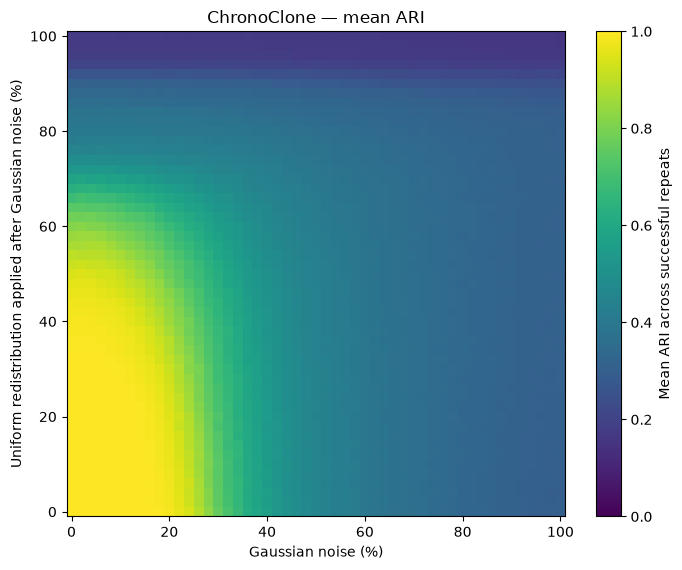

/path/to/ChronoClone/ChronoClone_paper/benchmarks/ode_noise/figures/validation_five_method/chronoclone_mean_ari_heatmap.svg


In [5]:
# Plot-specific shaping and full construction: ChronoClone mean-ARI heatmap
heat_source = summary.loc[summary["method"].eq('ChronoClone'), ["gaussian_pct", "uniform_pct", "ari_mean"]].copy()
heat = heat_source.pivot(index="uniform_pct", columns="gaussian_pct", values="ari_mean").sort_index().sort_index(axis=1)
assert heat.shape == (51, 51)
x = heat.columns.to_numpy(float)
y = heat.index.to_numpy(float)
x_edges = np.r_[x - 1.0, x[-1] + 1.0]
y_edges = np.r_[y - 1.0, y[-1] + 1.0]
values = np.ma.masked_invalid(heat.to_numpy(float))
fig, ax = plt.subplots(figsize=(7.1, 5.8))
ax.set_facecolor("#EEEEEE")
mesh = ax.pcolormesh(x_edges, y_edges, values, shading="flat", vmin=0, vmax=1, cmap="viridis")
if values.count() == 0:
    ax.text(50, 50, "No successful fits", ha="center", va="center", fontsize=12, color="#555555")
ax.set_xlim(-1, 101)
ax.set_ylim(-1, 101)
ax.set_xticks(np.arange(0, 101, 20))
ax.set_yticks(np.arange(0, 101, 20))
ax.set_xlabel("Gaussian noise (%)")
ax.set_ylabel("Uniform redistribution applied after Gaussian noise (%)")
ax.set_title('ChronoClone' + " — mean ARI")
colorbar = fig.colorbar(mesh, ax=ax)
colorbar.solids.set_rasterized(False)
colorbar.set_label("Mean ARI across successful repeats")
fig.tight_layout()
output_path = FIGURES / 'chronoclone_mean_ari_heatmap.svg'
fig.savefig(output_path, format="svg", bbox_inches="tight")
plt.show()
print(output_path)


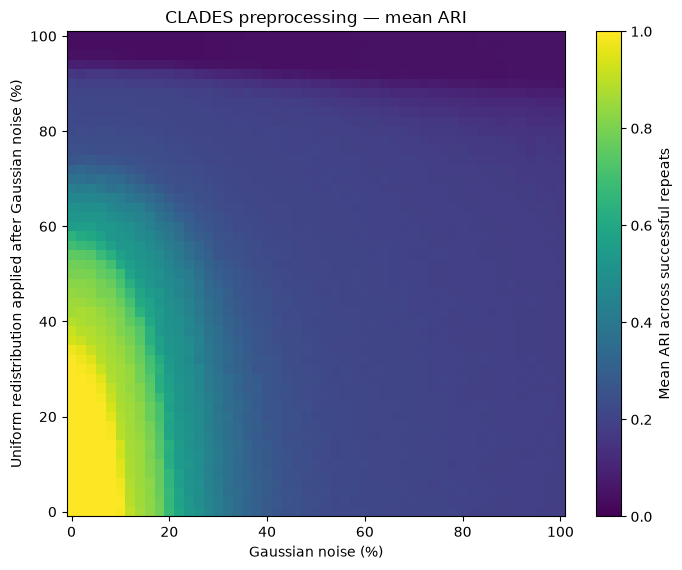

/path/to/ChronoClone/ChronoClone_paper/benchmarks/ode_noise/figures/validation_five_method/clades_preprocessing_mean_ari_heatmap.svg


In [6]:
# Plot-specific shaping and full construction: CLADES preprocessing mean-ARI heatmap
heat_source = summary.loc[summary["method"].eq('CLADES preprocessing'), ["gaussian_pct", "uniform_pct", "ari_mean"]].copy()
heat = heat_source.pivot(index="uniform_pct", columns="gaussian_pct", values="ari_mean").sort_index().sort_index(axis=1)
assert heat.shape == (51, 51)
x = heat.columns.to_numpy(float)
y = heat.index.to_numpy(float)
x_edges = np.r_[x - 1.0, x[-1] + 1.0]
y_edges = np.r_[y - 1.0, y[-1] + 1.0]
values = np.ma.masked_invalid(heat.to_numpy(float))
fig, ax = plt.subplots(figsize=(7.1, 5.8))
ax.set_facecolor("#EEEEEE")
mesh = ax.pcolormesh(x_edges, y_edges, values, shading="flat", vmin=0, vmax=1, cmap="viridis")
if values.count() == 0:
    ax.text(50, 50, "No successful fits", ha="center", va="center", fontsize=12, color="#555555")
ax.set_xlim(-1, 101)
ax.set_ylim(-1, 101)
ax.set_xticks(np.arange(0, 101, 20))
ax.set_yticks(np.arange(0, 101, 20))
ax.set_xlabel("Gaussian noise (%)")
ax.set_ylabel("Uniform redistribution applied after Gaussian noise (%)")
ax.set_title('CLADES preprocessing' + " — mean ARI")
colorbar = fig.colorbar(mesh, ax=ax)
colorbar.solids.set_rasterized(False)
colorbar.set_label("Mean ARI across successful repeats")
fig.tight_layout()
output_path = FIGURES / 'clades_preprocessing_mean_ari_heatmap.svg'
fig.savefig(output_path, format="svg", bbox_inches="tight")
plt.show()
print(output_path)


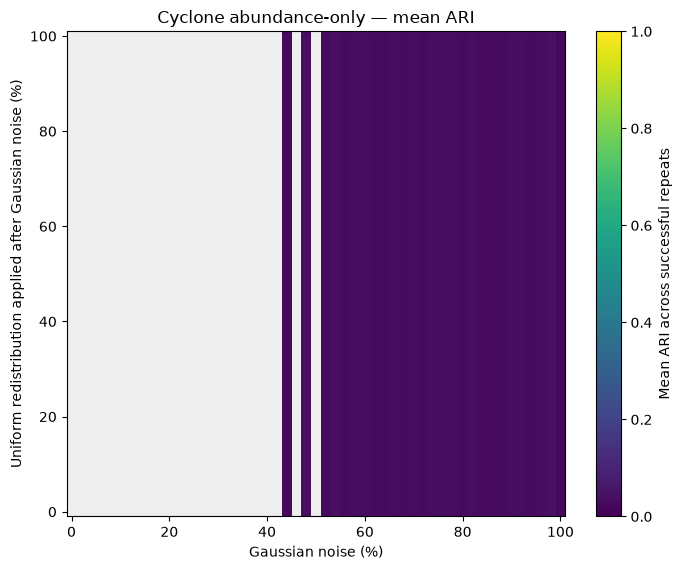

/path/to/ChronoClone/ChronoClone_paper/benchmarks/ode_noise/figures/validation_five_method/cyclone_abundance_only_mean_ari_heatmap.svg


In [7]:
# Plot-specific shaping and full construction: Cyclone abundance-only mean-ARI heatmap
heat_source = summary.loc[summary["method"].eq('Cyclone abundance-only'), ["gaussian_pct", "uniform_pct", "ari_mean"]].copy()
heat = heat_source.pivot(index="uniform_pct", columns="gaussian_pct", values="ari_mean").sort_index().sort_index(axis=1)
assert heat.shape == (51, 51)
x = heat.columns.to_numpy(float)
y = heat.index.to_numpy(float)
x_edges = np.r_[x - 1.0, x[-1] + 1.0]
y_edges = np.r_[y - 1.0, y[-1] + 1.0]
values = np.ma.masked_invalid(heat.to_numpy(float))
fig, ax = plt.subplots(figsize=(7.1, 5.8))
ax.set_facecolor("#EEEEEE")
mesh = ax.pcolormesh(x_edges, y_edges, values, shading="flat", vmin=0, vmax=1, cmap="viridis")
if values.count() == 0:
    ax.text(50, 50, "No successful fits", ha="center", va="center", fontsize=12, color="#555555")
ax.set_xlim(-1, 101)
ax.set_ylim(-1, 101)
ax.set_xticks(np.arange(0, 101, 20))
ax.set_yticks(np.arange(0, 101, 20))
ax.set_xlabel("Gaussian noise (%)")
ax.set_ylabel("Uniform redistribution applied after Gaussian noise (%)")
ax.set_title('Cyclone abundance-only' + " — mean ARI")
colorbar = fig.colorbar(mesh, ax=ax)
colorbar.solids.set_rasterized(False)
colorbar.set_label("Mean ARI across successful repeats")
fig.tight_layout()
output_path = FIGURES / 'cyclone_abundance_only_mean_ari_heatmap.svg'
fig.savefig(output_path, format="svg", bbox_inches="tight")
plt.show()
print(output_path)


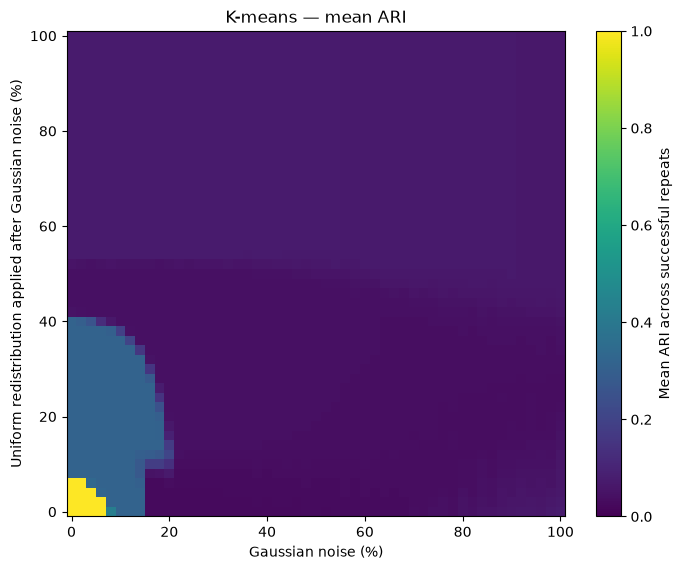

/path/to/ChronoClone/ChronoClone_paper/benchmarks/ode_noise/figures/validation_five_method/kmeans_mean_ari_heatmap.svg


In [8]:
# Plot-specific shaping and full construction: K-means mean-ARI heatmap
heat_source = summary.loc[summary["method"].eq('K-means'), ["gaussian_pct", "uniform_pct", "ari_mean"]].copy()
heat = heat_source.pivot(index="uniform_pct", columns="gaussian_pct", values="ari_mean").sort_index().sort_index(axis=1)
assert heat.shape == (51, 51)
x = heat.columns.to_numpy(float)
y = heat.index.to_numpy(float)
x_edges = np.r_[x - 1.0, x[-1] + 1.0]
y_edges = np.r_[y - 1.0, y[-1] + 1.0]
values = np.ma.masked_invalid(heat.to_numpy(float))
fig, ax = plt.subplots(figsize=(7.1, 5.8))
ax.set_facecolor("#EEEEEE")
mesh = ax.pcolormesh(x_edges, y_edges, values, shading="flat", vmin=0, vmax=1, cmap="viridis")
if values.count() == 0:
    ax.text(50, 50, "No successful fits", ha="center", va="center", fontsize=12, color="#555555")
ax.set_xlim(-1, 101)
ax.set_ylim(-1, 101)
ax.set_xticks(np.arange(0, 101, 20))
ax.set_yticks(np.arange(0, 101, 20))
ax.set_xlabel("Gaussian noise (%)")
ax.set_ylabel("Uniform redistribution applied after Gaussian noise (%)")
ax.set_title('K-means' + " — mean ARI")
colorbar = fig.colorbar(mesh, ax=ax)
colorbar.solids.set_rasterized(False)
colorbar.set_label("Mean ARI across successful repeats")
fig.tight_layout()
output_path = FIGURES / 'kmeans_mean_ari_heatmap.svg'
fig.savefig(output_path, format="svg", bbox_inches="tight")
plt.show()
print(output_path)


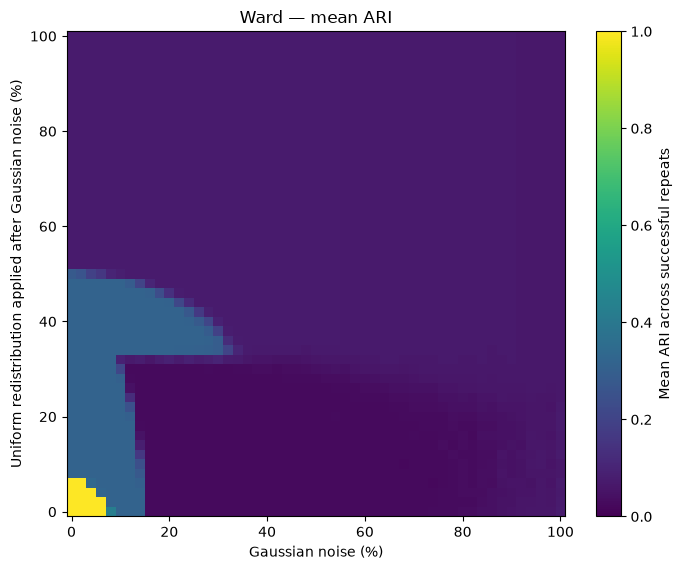

/path/to/ChronoClone/ChronoClone_paper/benchmarks/ode_noise/figures/validation_five_method/ward_mean_ari_heatmap.svg


In [9]:
# Plot-specific shaping and full construction: Ward mean-ARI heatmap
heat_source = summary.loc[summary["method"].eq('Ward'), ["gaussian_pct", "uniform_pct", "ari_mean"]].copy()
heat = heat_source.pivot(index="uniform_pct", columns="gaussian_pct", values="ari_mean").sort_index().sort_index(axis=1)
assert heat.shape == (51, 51)
x = heat.columns.to_numpy(float)
y = heat.index.to_numpy(float)
x_edges = np.r_[x - 1.0, x[-1] + 1.0]
y_edges = np.r_[y - 1.0, y[-1] + 1.0]
values = np.ma.masked_invalid(heat.to_numpy(float))
fig, ax = plt.subplots(figsize=(7.1, 5.8))
ax.set_facecolor("#EEEEEE")
mesh = ax.pcolormesh(x_edges, y_edges, values, shading="flat", vmin=0, vmax=1, cmap="viridis")
if values.count() == 0:
    ax.text(50, 50, "No successful fits", ha="center", va="center", fontsize=12, color="#555555")
ax.set_xlim(-1, 101)
ax.set_ylim(-1, 101)
ax.set_xticks(np.arange(0, 101, 20))
ax.set_yticks(np.arange(0, 101, 20))
ax.set_xlabel("Gaussian noise (%)")
ax.set_ylabel("Uniform redistribution applied after Gaussian noise (%)")
ax.set_title('Ward' + " — mean ARI")
colorbar = fig.colorbar(mesh, ax=ax)
colorbar.solids.set_rasterized(False)
colorbar.set_label("Mean ARI across successful repeats")
fig.tight_layout()
output_path = FIGURES / 'ward_mean_ari_heatmap.svg'
fig.savefig(output_path, format="svg", bbox_inches="tight")
plt.show()
print(output_path)


## Applicability, eligibility, and native selection

Success fractions expose method applicability separately from accuracy.
Recovered K is descriptive of each truth-blind native selector. Selection
parameters are not numerically comparable across methods (for example,
ChronoClone consensus threshold versus CLADES resolution versus requested K),
so their axis values are tabulated rather than placed on one scale.


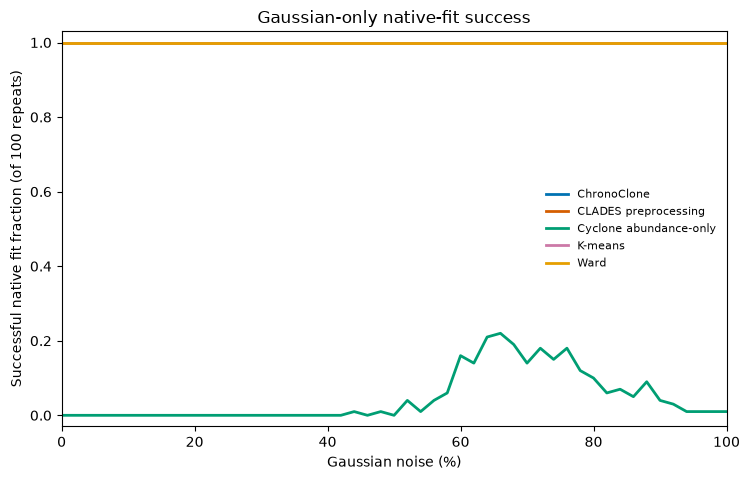

/path/to/ChronoClone/ChronoClone_paper/benchmarks/ode_noise/figures/validation_five_method/gaussian_only_method_success_fraction.svg


In [10]:
# Plot-specific shaping and full construction: Gaussian-only native-fit success
success_axis = completeness.loc[completeness["uniform_pct"].eq(0)].copy()
fig, ax = plt.subplots(figsize=(7.6, 4.9))
for method in METHODS:
    data = success_axis.loc[success_axis["method"].eq(method)].sort_values('gaussian_pct')
    x = data['gaussian_pct'].to_numpy(float)
    y = data["success_fraction"].to_numpy(float)
    ax.plot(x, y, color=COLORS[method], linewidth=2.0, label=method)
ax.set_xlim(0, 100)
ax.set_ylim(-0.03, 1.03)
ax.set_xlabel('Gaussian noise (%)')
ax.set_ylabel("Successful native fit fraction (of 100 repeats)")
ax.set_title('Gaussian-only native-fit success')
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
output_path = FIGURES / 'gaussian_only_method_success_fraction.svg'
fig.savefig(output_path, format="svg", bbox_inches="tight")
plt.show()
print(output_path)


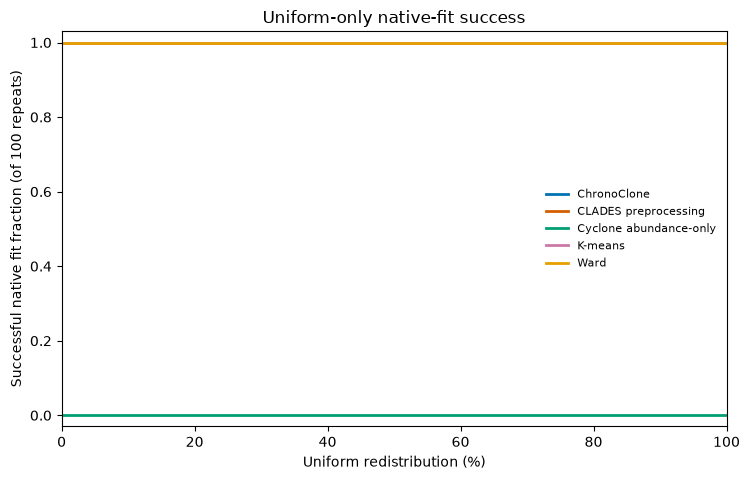

/path/to/ChronoClone/ChronoClone_paper/benchmarks/ode_noise/figures/validation_five_method/uniform_only_method_success_fraction.svg


In [11]:
# Plot-specific shaping and full construction: Uniform-only native-fit success
success_axis = completeness.loc[completeness["gaussian_pct"].eq(0)].copy()
fig, ax = plt.subplots(figsize=(7.6, 4.9))
for method in METHODS:
    data = success_axis.loc[success_axis["method"].eq(method)].sort_values('uniform_pct')
    x = data['uniform_pct'].to_numpy(float)
    y = data["success_fraction"].to_numpy(float)
    ax.plot(x, y, color=COLORS[method], linewidth=2.0, label=method)
ax.set_xlim(0, 100)
ax.set_ylim(-0.03, 1.03)
ax.set_xlabel('Uniform redistribution (%)')
ax.set_ylabel("Successful native fit fraction (of 100 repeats)")
ax.set_title('Uniform-only native-fit success')
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
output_path = FIGURES / 'uniform_only_method_success_fraction.svg'
fig.savefig(output_path, format="svg", bbox_inches="tight")
plt.show()
print(output_path)


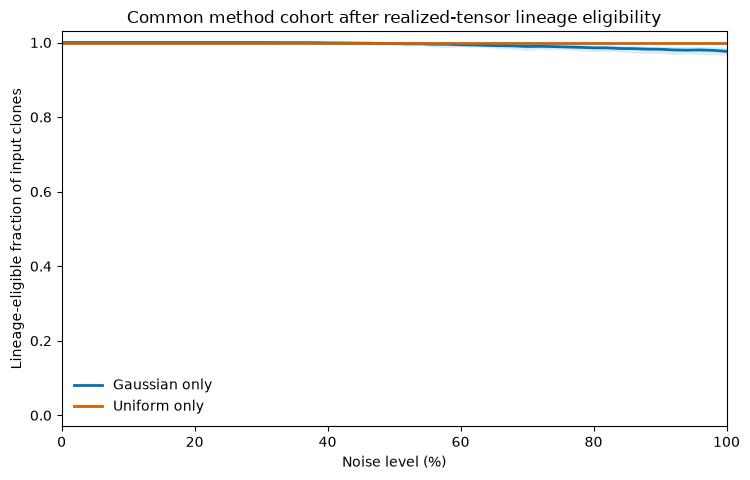

/path/to/ChronoClone/ChronoClone_paper/benchmarks/ode_noise/figures/validation_five_method/isolated_axes_eligible_clone_fraction.svg


In [12]:
# Plot-specific shaping and full construction: common eligibility on both isolated axes
gaussian_eligibility = eligibility.loc[eligibility["uniform_pct"].eq(0)].sort_values("gaussian_pct").copy()
uniform_eligibility = eligibility.loc[eligibility["gaussian_pct"].eq(0)].sort_values("uniform_pct").copy()
fig, ax = plt.subplots(figsize=(7.6, 4.9))
for label, data, x_column, color in [
    ("Gaussian only", gaussian_eligibility, "gaussian_pct", "#0072B2"),
    ("Uniform only", uniform_eligibility, "uniform_pct", "#D55E00"),
]:
    x = data[x_column].to_numpy(float)
    mean = data["eligible_fraction_mean"].to_numpy(float)
    lower = data["eligible_fraction_q025"].to_numpy(float)
    upper = data["eligible_fraction_q975"].to_numpy(float)
    ax.plot(x, mean, color=color, linewidth=2.0, label=label)
    ax.fill_between(x, lower, upper, color=color, alpha=0.14, linewidth=0)
ax.set_xlim(0, 100)
ax.set_ylim(-0.03, 1.03)
ax.set_xlabel("Noise level (%)")
ax.set_ylabel("Lineage-eligible fraction of input clones")
ax.set_title("Common method cohort after realized-tensor lineage eligibility")
ax.legend(frameon=False)
fig.tight_layout()
output_path = FIGURES / "isolated_axes_eligible_clone_fraction.svg"
fig.savefig(output_path, format="svg", bbox_inches="tight")
plt.show()
print(output_path)


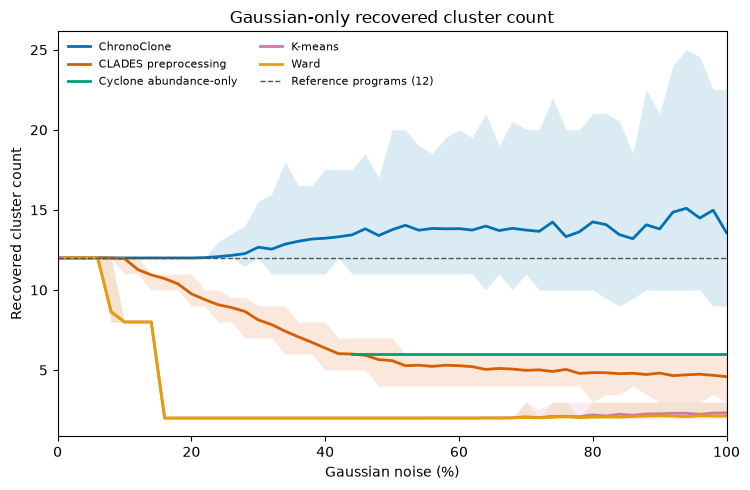

/path/to/ChronoClone/ChronoClone_paper/benchmarks/ode_noise/figures/validation_five_method/gaussian_only_recovered_k.svg


In [13]:
# Plot-specific shaping and full construction: Gaussian-only recovered cluster count
k_axis = summary.loc[summary["uniform_pct"].eq(0)].copy()
fig, ax = plt.subplots(figsize=(7.6, 5.0))
for method in METHODS:
    data = k_axis.loc[k_axis["method"].eq(method)].sort_values('gaussian_pct')
    x = data['gaussian_pct'].to_numpy(float)
    mean = data["recovered_k_mean"].to_numpy(float)
    lower = data["recovered_k_q025"].to_numpy(float)
    upper = data["recovered_k_q975"].to_numpy(float)
    finite = np.isfinite(mean)
    if finite.any():
        ax.plot(x[finite], mean[finite], color=COLORS[method], linewidth=2.0, label=method)
        band = finite & np.isfinite(lower) & np.isfinite(upper)
        if band.any():
            ax.fill_between(x[band], lower[band], upper[band], color=COLORS[method], alpha=0.14, linewidth=0)
ax.axhline(12, color="#555555", linewidth=1, linestyle="--", label="Reference programs (12)")
ax.set_xlim(0, 100)
ax.set_xlabel('Gaussian noise (%)')
ax.set_ylabel("Recovered cluster count")
ax.set_title('Gaussian-only recovered cluster count')
ax.legend(frameon=False, fontsize=8, ncol=2)
fig.tight_layout()
output_path = FIGURES / 'gaussian_only_recovered_k.svg'
fig.savefig(output_path, format="svg", bbox_inches="tight")
plt.show()
print(output_path)


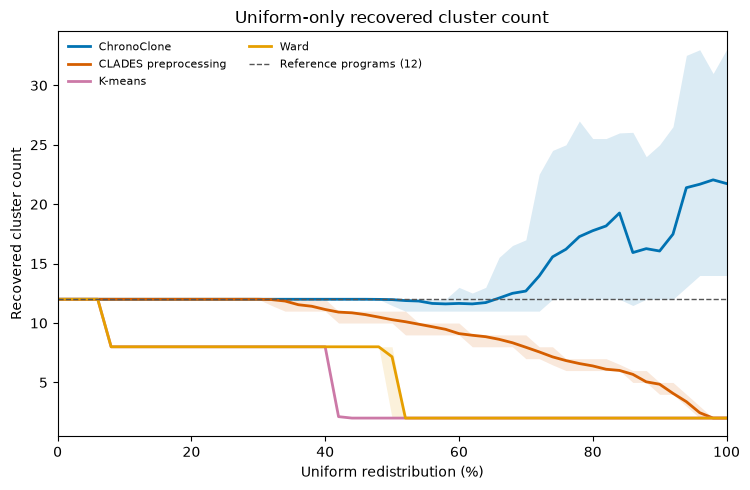

/path/to/ChronoClone/ChronoClone_paper/benchmarks/ode_noise/figures/validation_five_method/uniform_only_recovered_k.svg


In [14]:
# Plot-specific shaping and full construction: Uniform-only recovered cluster count
k_axis = summary.loc[summary["gaussian_pct"].eq(0)].copy()
fig, ax = plt.subplots(figsize=(7.6, 5.0))
for method in METHODS:
    data = k_axis.loc[k_axis["method"].eq(method)].sort_values('uniform_pct')
    x = data['uniform_pct'].to_numpy(float)
    mean = data["recovered_k_mean"].to_numpy(float)
    lower = data["recovered_k_q025"].to_numpy(float)
    upper = data["recovered_k_q975"].to_numpy(float)
    finite = np.isfinite(mean)
    if finite.any():
        ax.plot(x[finite], mean[finite], color=COLORS[method], linewidth=2.0, label=method)
        band = finite & np.isfinite(lower) & np.isfinite(upper)
        if band.any():
            ax.fill_between(x[band], lower[band], upper[band], color=COLORS[method], alpha=0.14, linewidth=0)
ax.axhline(12, color="#555555", linewidth=1, linestyle="--", label="Reference programs (12)")
ax.set_xlim(0, 100)
ax.set_xlabel('Uniform redistribution (%)')
ax.set_ylabel("Recovered cluster count")
ax.set_title('Uniform-only recovered cluster count')
ax.legend(frameon=False, fontsize=8, ncol=2)
fig.tight_layout()
output_path = FIGURES / 'uniform_only_recovered_k.svg'
fig.savefig(output_path, format="svg", bbox_inches="tight")
plt.show()
print(output_path)


In [15]:
selector_axes = pd.concat(
    [
        summary.loc[summary["uniform_pct"].eq(0), ["method", "gaussian_pct", "selection_parameter_mean", "selected_silhouette_mean", "recovered_k_mean"]].assign(axis="Gaussian only", noise_pct=lambda x: x["gaussian_pct"]),
        summary.loc[summary["gaussian_pct"].eq(0), ["method", "uniform_pct", "selection_parameter_mean", "selected_silhouette_mean", "recovered_k_mean"]].assign(axis="Uniform only", noise_pct=lambda x: x["uniform_pct"]),
    ],
    ignore_index=True,
)
selector_endpoints = selector_axes.loc[selector_axes["noise_pct"].isin([0, 10, 20, 50, 100]), ["axis", "noise_pct", "method", "selection_parameter_mean", "selected_silhouette_mean", "recovered_k_mean"]]
display(selector_endpoints.sort_values(["axis", "noise_pct", "method"]))


,axis,noise_pct,method,selection_parameter_mean,selected_silhouette_mean,recovered_k_mean
51,Gaussian only,0,CLADES preprocessing,0.2500,NaN,12.00
0,Gaussian only,0,ChronoClone,0.0100,1.000000,12.00
102,Gaussian only,0,Cyclone abundance-only,NaN,NaN,NaN
153,Gaussian only,0,K-means,12.0000,1.000000,12.00
204,Gaussian only,0,Ward,12.0000,1.000000,12.00
56,Gaussian only,10,CLADES preprocessing,0.2500,NaN,11.96
5,Gaussian only,10,ChronoClone,0.6292,0.701734,12.00
107,Gaussian only,10,Cyclone abundance-only,NaN,NaN,NaN
158,Gaussian only,10,K-means,8.0000,0.742205,8.00
209,Gaussian only,10,Ward,8.0000,0.742205,8.00


## ChronoClone selection and common retained-set sensitivity

ChronoClone conditional accuracy is paired with retained-clone coverage. For
the sensitivity curves, every already-fitted comparator is rescored on the
same ChronoClone-retained IDs without refitting. The plotted difference is a
within-method denominator sensitivity, not a filtered-ChronoClone superiority
contrast.


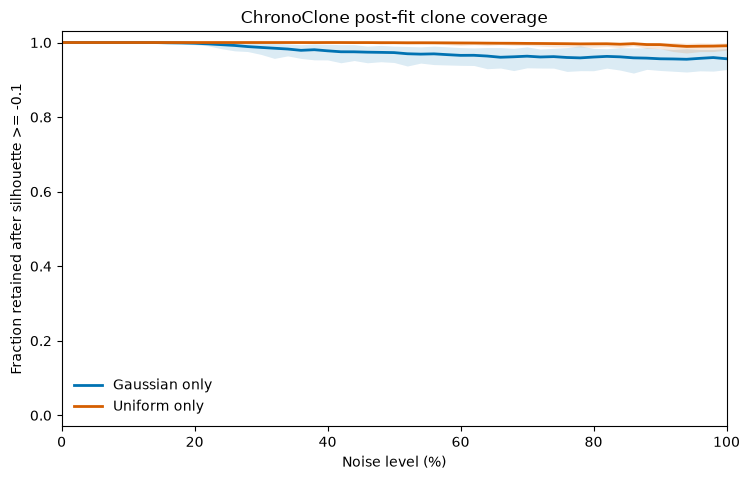

/path/to/ChronoClone/ChronoClone_paper/benchmarks/ode_noise/figures/validation_five_method/chronoclone_isolated_axes_postfit_coverage.svg


In [16]:
# Plot-specific shaping and full construction: ChronoClone post-fit coverage
gaussian_coverage = selective.loc[selective["uniform_pct"].eq(0)].sort_values("gaussian_pct").copy()
uniform_coverage = selective.loc[selective["gaussian_pct"].eq(0)].sort_values("uniform_pct").copy()
fig, ax = plt.subplots(figsize=(7.6, 4.9))
for label, data, x_column, color in [
    ("Gaussian only", gaussian_coverage, "gaussian_pct", "#0072B2"),
    ("Uniform only", uniform_coverage, "uniform_pct", "#D55E00"),
]:
    x = data[x_column].to_numpy(float)
    mean = data["postfit_retained_fraction_of_eligible_mean"].to_numpy(float)
    lower = data["postfit_retained_fraction_of_eligible_q025"].to_numpy(float)
    upper = data["postfit_retained_fraction_of_eligible_q975"].to_numpy(float)
    ax.plot(x, mean, color=color, linewidth=2.0, label=label)
    ax.fill_between(x, lower, upper, color=color, alpha=0.14, linewidth=0)
ax.set_xlim(0, 100)
ax.set_ylim(-0.03, 1.03)
ax.set_xlabel("Noise level (%)")
ax.set_ylabel("Fraction retained after silhouette >= -0.1")
ax.set_title("ChronoClone post-fit clone coverage")
ax.legend(frameon=False)
fig.tight_layout()
output_path = FIGURES / "chronoclone_isolated_axes_postfit_coverage.svg"
fig.savefig(output_path, format="svg", bbox_inches="tight")
plt.show()
print(output_path)


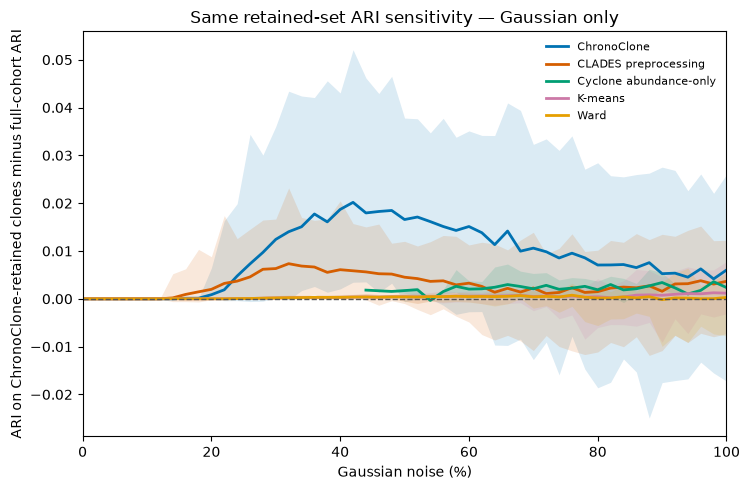

/path/to/ChronoClone/ChronoClone_paper/benchmarks/ode_noise/figures/validation_five_method/gaussian_only_same_retained_ari_sensitivity.svg


In [17]:
# Plot-specific shaping and full construction: Same retained-set ARI sensitivity — Gaussian only
sensitivity_axis = same_retained.loc[same_retained["uniform_pct"].eq(0)].copy()
fig, ax = plt.subplots(figsize=(7.6, 5.0))
for method in METHODS:
    data = sensitivity_axis.loc[sensitivity_axis["method"].eq(method)].sort_values('gaussian_pct')
    x = data['gaussian_pct'].to_numpy(float)
    mean = data["shared_retained_minus_full_ari_mean"].to_numpy(float)
    lower = data["shared_retained_minus_full_ari_q025"].to_numpy(float)
    upper = data["shared_retained_minus_full_ari_q975"].to_numpy(float)
    finite = np.isfinite(mean)
    if finite.any():
        ax.plot(x[finite], mean[finite], color=COLORS[method], linewidth=2.0, label=method)
        band = finite & np.isfinite(lower) & np.isfinite(upper)
        if band.any():
            ax.fill_between(x[band], lower[band], upper[band], color=COLORS[method], alpha=0.14, linewidth=0)
ax.axhline(0, color="#555555", linewidth=1, linestyle="--")
ax.set_xlim(0, 100)
ax.set_xlabel('Gaussian noise (%)')
ax.set_ylabel("ARI on ChronoClone-retained clones minus full-cohort ARI")
ax.set_title('Same retained-set ARI sensitivity — Gaussian only')
handles, labels = ax.get_legend_handles_labels()
if handles:
    ax.legend(handles, labels, frameon=False, fontsize=8)
fig.tight_layout()
output_path = FIGURES / 'gaussian_only_same_retained_ari_sensitivity.svg'
fig.savefig(output_path, format="svg", bbox_inches="tight")
plt.show()
print(output_path)


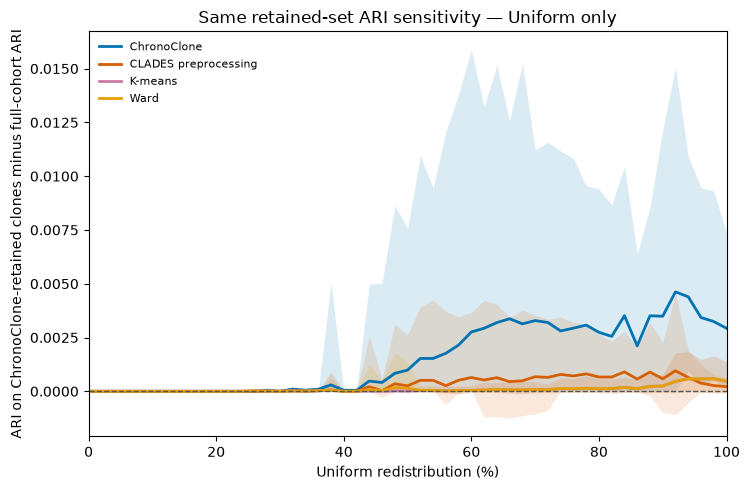

/path/to/ChronoClone/ChronoClone_paper/benchmarks/ode_noise/figures/validation_five_method/uniform_only_same_retained_ari_sensitivity.svg


In [18]:
# Plot-specific shaping and full construction: Same retained-set ARI sensitivity — Uniform only
sensitivity_axis = same_retained.loc[same_retained["gaussian_pct"].eq(0)].copy()
fig, ax = plt.subplots(figsize=(7.6, 5.0))
for method in METHODS:
    data = sensitivity_axis.loc[sensitivity_axis["method"].eq(method)].sort_values('uniform_pct')
    x = data['uniform_pct'].to_numpy(float)
    mean = data["shared_retained_minus_full_ari_mean"].to_numpy(float)
    lower = data["shared_retained_minus_full_ari_q025"].to_numpy(float)
    upper = data["shared_retained_minus_full_ari_q975"].to_numpy(float)
    finite = np.isfinite(mean)
    if finite.any():
        ax.plot(x[finite], mean[finite], color=COLORS[method], linewidth=2.0, label=method)
        band = finite & np.isfinite(lower) & np.isfinite(upper)
        if band.any():
            ax.fill_between(x[band], lower[band], upper[band], color=COLORS[method], alpha=0.14, linewidth=0)
ax.axhline(0, color="#555555", linewidth=1, linestyle="--")
ax.set_xlim(0, 100)
ax.set_xlabel('Uniform redistribution (%)')
ax.set_ylabel("ARI on ChronoClone-retained clones minus full-cohort ARI")
ax.set_title('Same retained-set ARI sensitivity — Uniform only')
handles, labels = ax.get_legend_handles_labels()
if handles:
    ax.legend(handles, labels, frameon=False, fontsize=8)
fig.tight_layout()
output_path = FIGURES / 'uniform_only_same_retained_ari_sensitivity.svg'
fig.savefig(output_path, format="svg", bbox_inches="tight")
plt.show()
print(output_path)


In [19]:
selective_endpoints = pd.concat(
    [
        selective.loc[selective["uniform_pct"].eq(0)].assign(axis="Gaussian only", noise_pct=lambda x: x["gaussian_pct"]),
        selective.loc[selective["gaussian_pct"].eq(0)].assign(axis="Uniform only", noise_pct=lambda x: x["uniform_pct"]),
    ],
    ignore_index=True,
)
selective_columns = [
    "axis", "noise_pct", "postfit_retained_fraction_of_eligible_mean",
    "shared_retained_subset_ari_mean", "postfit_retained_k_mean",
    "postfit_clusters_lost_mean", "n_postfilter_ok", "n_postfilter_all_abstained",
    "n_postfilter_insufficient", "n_postfilter_other",
]
display(selective_endpoints.loc[selective_endpoints["noise_pct"].isin([0, 10, 20, 50, 100]), selective_columns].sort_values(["axis", "noise_pct"]))
failure_totals = completeness.groupby("method", sort=False)[["n_success", "n_method_failure"]].sum().reset_index()
display(failure_totals)
if len(failures):
    display(failures.groupby(["method", "error_type"], as_index=False)["count"].sum())
else:
    display(pd.DataFrame({"status": ["No native method failures"]}))


,axis,noise_pct,postfit_retained_fraction_of_eligible_mean,shared_retained_subset_ari_mean,postfit_retained_k_mean,postfit_clusters_lost_mean,n_postfilter_ok,n_postfilter_all_abstained,n_postfilter_insufficient,n_postfilter_other
0,Gaussian only,0,1.000000,1.000000,12.00,0.0,100,0,0,0
5,Gaussian only,10,1.000000,0.999954,12.00,0.0,100,0,0,0
10,Gaussian only,20,0.998027,0.986881,12.00,0.0,100,0,0,0
25,Gaussian only,50,0.972944,0.471111,13.76,0.0,100,0,0,0
50,Gaussian only,100,0.956422,0.306951,13.58,0.0,100,0,0,0
51,Uniform only,0,1.000000,1.000000,12.00,0.0,100,0,0,0
56,Uniform only,10,1.000000,1.000000,12.00,0.0,100,0,0,0
61,Uniform only,20,1.000000,0.999947,12.00,0.0,100,0,0,0
76,Uniform only,50,0.999574,0.942997,11.97,0.0,100,0,0,0
101,Uniform only,100,0.991315,0.175328,21.74,0.0,100,0,0,0


,method,n_success,n_method_failure
0,ChronoClone,260100,0
1,CLADES preprocessing,260100,0
2,Cyclone abundance-only,11934,248166
3,K-means,260100,0
4,Ward,260100,0


,method,error_type,count
0,Cyclone abundance-only,NativeSelectionFailure,248166


## Scope limits

- CLADES denotes its published mouse preprocessing partition, not its
  NeuralODE/Gillespie stages.
- Cyclone is abundance-only here; its failures are applicability outcomes.
- K-means and Ward use a predeclared truth-blind silhouette K grid.
- The five methods retain their native feature/selection rules, so the result
  is not an isolated comparison of clustering machinery.
- The deterministic 12-program generator is a technical-noise stress test,
  not evidence of real-data biological generality.


In [20]:
expected_figures = {
    "gaussian_only_mean_ari_by_method.svg",
    "uniform_only_mean_ari_by_method.svg",
    "chronoclone_mean_ari_heatmap.svg",
    "clades_preprocessing_mean_ari_heatmap.svg",
    "cyclone_abundance_only_mean_ari_heatmap.svg",
    "kmeans_mean_ari_heatmap.svg",
    "ward_mean_ari_heatmap.svg",
    "gaussian_only_method_success_fraction.svg",
    "uniform_only_method_success_fraction.svg",
    "isolated_axes_eligible_clone_fraction.svg",
    "gaussian_only_recovered_k.svg",
    "uniform_only_recovered_k.svg",
    "chronoclone_isolated_axes_postfit_coverage.svg",
    "gaussian_only_same_retained_ari_sensitivity.svg",
    "uniform_only_same_retained_ari_sensitivity.svg",
}
svg_rows = []
for name in sorted(expected_figures):
    path = FIGURES / name
    root = ET.parse(path).getroot()
    tags = [element.tag.rsplit("}", 1)[-1] for element in root.iter()]
    svg_rows.append({
        "figure": name,
        "exists": path.is_file(),
        "has_live_text": "text" in tags,
        "has_embedded_raster": "image" in tags,
        "sha256": sha256(path),
        "bytes": path.stat().st_size,
    })
svg_validation = pd.DataFrame(svg_rows)
assert len(svg_validation) == 15
assert svg_validation["exists"].all()
assert svg_validation["has_live_text"].all()
assert not svg_validation["has_embedded_raster"].any()
display(svg_validation)


,figure,exists,has_live_text,has_embedded_raster,sha256,bytes
0,chronoclone_isolated_axes_postfit_coverage.svg,True,True,False,687ce0177d53c88ce87b2469a22b3792331770364faaba...,19938
1,chronoclone_mean_ari_heatmap.svg,True,True,False,42c7856ed63765e4b127e717bef1707684d3beb210e13e...,561485
2,clades_preprocessing_mean_ari_heatmap.svg,True,True,False,72e8e9ae6dd146fa5f444f67cb4a171202eccb8e68ef8b...,561494
3,cyclone_abundance_only_mean_ari_heatmap.svg,True,True,False,898f84834cf91cc3883a9b926469ec98c0b288a22b92ea...,557824
4,gaussian_only_mean_ari_by_method.svg,True,True,False,8caad47e1e6bf9aad835336953dfb550dd805630167d67...,32529
5,gaussian_only_method_success_fraction.svg,True,True,False,35be39217271e3ecac6a1642cf66ed7691326bc3a53e84...,19910
6,gaussian_only_recovered_k.svg,True,True,False,3da4202e60d25d71a20dee811959922316901903ff7a14...,32775
7,gaussian_only_same_retained_ari_sensitivity.svg,True,True,False,0e09fad3b41e865b882e3183a77bc0fa2918ca066d88bb...,34035
8,isolated_axes_eligible_clone_fraction.svg,True,True,False,87336f88bc3d25c701a018499dfbc07cab2ec62e3588e8...,19965
9,kmeans_mean_ari_heatmap.svg,True,True,False,2a82d7da7ad083c40effb22c9017282b00f4e5497c0ce3...,561742
